In [1]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import tensorflow as tf
import matplotlib.pyplot as plt


In [21]:
mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='liac-arff')
x = mnist.data.astype('float32')
y = mnist.target.astype('int32')
print(x.shape)
print(y.shape)
print(x[0].shape)

(70000, 784)
(70000,)
(784,)


In [32]:
x=x/255 #NORMALIZAMOS LAS IMÁGENES
x=x.reshape(-1,28,28,1)
print("nueva forma de x", x.shape)
print("nueva forma de x", x[0].shape)

nueva forma de x (70000, 28, 28, 1)
nueva forma de x (28, 28, 1)


In [27]:
x_train, x_test, y_train, y_test= train_test_split(x,y,test_size=0.2, random_state=42)

In [97]:
#RNA CONVOLUCIONAL
model= tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(28,28,1)), #OJO: Las imágenes ya NO están aplanadas
    tf.keras.layers.Conv2D(16, 3, activation='relu'),   #devuelve un mapa de caracterisitcas el doble
    tf.keras.layers.MaxPooling2D(), #reducimos la dimensionalidad del mapa de caraterísticas
    tf.keras.layers.Conv2D(38, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),   #aprender los patrones mas complejos
    tf.keras.layers.Conv2D(160, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),




    tf.keras.layers.Conv2D(200, 3, activation='relu'),
    tf.keras.layers.MaxPooling2D(),

    #tf.keras.layers.Conv2D(128, 3, activation='relu'),
    #tf.keras.layers.MaxPooling2D(),



    tf.keras.layers.Flatten(), #aplanamos nuevamente la imagen para procesarla en capas densas
    #LA PREDICCIÓN FINAL LA TOMAN LAS CAPAS DENSAS

    #LA PREDICCIÓN FINAL LA TOMAN LAS CAPAS DENSAS
    #tf.keras.layers.Dense(128, activation='relu'),  #procesamiento

    tf.keras.layers.Dense(200, 160, activation='relu'), 
    tf.keras.layers.Dense(20, activation='softmax'),  #capa densa
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])  #activacion

TypeError: Dense.__init__() got multiple values for argument 'activation'

In [86]:
model.fit(x_train, y_train, epochs=10)

Epoch 1/10
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9277 - loss: 0.2306
Epoch 2/10
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9763 - loss: 0.0774
Epoch 3/10
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9826 - loss: 0.0557
Epoch 4/10
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9866 - loss: 0.0443
Epoch 5/10
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9893 - loss: 0.0357
Epoch 6/10
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9907 - loss: 0.0290
Epoch 7/10
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9924 - loss: 0.0235
Epoch 8/10
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9933 - loss: 0.0201
Epoch 9/10
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9943 - loss: 0.0167
Epoch 10/10
1750/1750 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9950 - loss: 0.0153


In [87]:
y_pred= model.predict(x_test)
print(y_pred.argmax(1)[:8])#extrae  .saldrian puntos sucesivos
print(y_test[:8])  #las prediciones de las primeras 8

438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
[8 4 8 7 7 0 6 2]
[8 4 8 7 7 0 6 2]


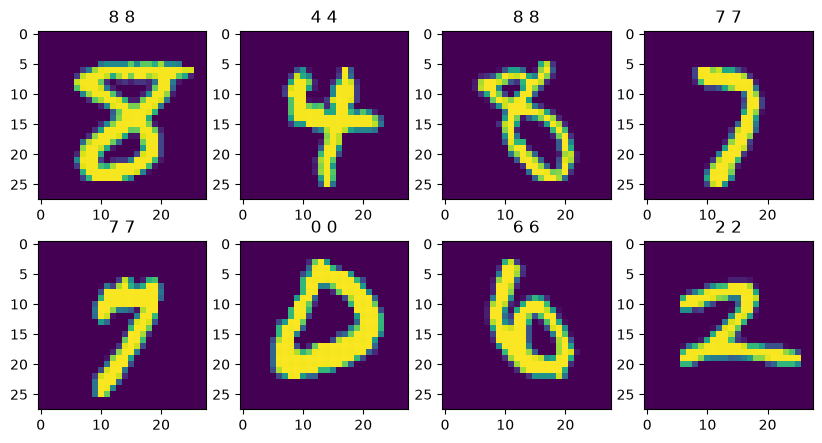

In [88]:
plt.figure(figsize=(10,5))
for i in range(8):
  plt.subplot(2,4,i+1)
  plt.imshow(x_test[i].reshape(28,28))#la imagen estaba aplanada, por lo tanto le quitamos dicha característica
  plt.title(str(y_test[i])+' '+str(y_pred.argmax(1)[i]))

In [90]:
print(accuracy_score(y_test, y_pred.argmax(1)))
print(classification_report(y_test, y_pred.argmax(1)))

0.9856428571428572
              precision    recall  f1-score   support

           0       1.00      0.99      0.99      1343
           1       0.99      1.00      0.99      1600
           2       0.98      0.98      0.98      1380
           3       0.99      0.98      0.99      1433
           4       0.97      1.00      0.98      1295
           5       0.98      0.99      0.99      1273
           6       0.99      0.99      0.99      1396
           7       0.98      0.98      0.98      1503
           8       0.99      0.98      0.98      1357
           9       0.99      0.97      0.98      1420

    accuracy                           0.99     14000
   macro avg       0.99      0.99      0.99     14000
weighted avg       0.99      0.99      0.99     14000

